<a href="https://colab.research.google.com/github/Aravind69420/github-slideshow/blob/main/Test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Download

In [2]:
!pip install opendatasets --quiet
import opendatasets as od
od.download ("https://www.kaggle.com/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images")

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: Dimes69
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images


100%|██████████| 105M/105M [00:00<00:00, 756MB/s] 

Imports

In [3]:
import torch
from torch import nn
from torch.optim import Adam
from torchvision.transforms import transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd
import numpy as np
import os

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device available: ", device)


Device available:  cpu


Data Paths

In [4]:
image_path = []
labels = []

for i in os.listdir("/content/cifake-real-and-ai-generated-synthetic-images"):
  for label in os.listdir(f"/content/cifake-real-and-ai-generated-synthetic-images/{i}"):
    for image in os.listdir(f"/content/cifake-real-and-ai-generated-synthetic-images/{i}/{label}"):
      image_path.append(f"/content/cifake-real-and-ai-generated-synthetic-images/{i}/{label}/{image}")
      labels.append(label)

data_df = pd.DataFrame(zip(image_path, labels), columns= ["image_path", "labels"])

print(data_df["labels"].unique())
data_df.head()

['FAKE' 'REAL']


,image_path,labels
0,/content/cifake-real-and-ai-generated-syntheti...,FAKE
1,/content/cifake-real-and-ai-generated-syntheti...,FAKE
2,/content/cifake-real-and-ai-generated-syntheti...,FAKE
3,/content/cifake-real-and-ai-generated-syntheti...,FAKE
4,/content/cifake-real-and-ai-generated-syntheti...,FAKE


Data Classification

In [5]:
train = data_df.sample(frac = 0.7)
test = data_df.drop(train.index)

val = test.sample(frac = 0.5)
test = test.drop(val.index)

print(train.shape)
print(test.shape)
print(val.shape)

(84000, 2)
(18000, 2)
(18000, 2)


Preprocessing

In [6]:
label_encoder = LabelEncoder()
label_encoder.fit(train["labels"])

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.ConvertImageDtype(torch.float)
])

Custom Dataset Class

In [7]:
class CustomImageDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.transform = transform
        self.labels = torch.tensor(label_encoder.transform(dataframe['labels'])).to(device)

    def __len__(self):
        return self.dataframe.shape[0]

    def __getitem__(self, idx):
        img_path = self.dataframe.iloc[idx, 0]
        label = self.labels[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
          image = self.transform(image).to(device)

        return image, label

Dataset Objects

In [8]:
train_dataset = CustomImageDataset(dataframe=train, transform=transform)
val_dataset = CustomImageDataset(dataframe=val, transform=transform)
test_dataset = CustomImageDataset(dataframe=test, transform=transform)

Visualization Of Images

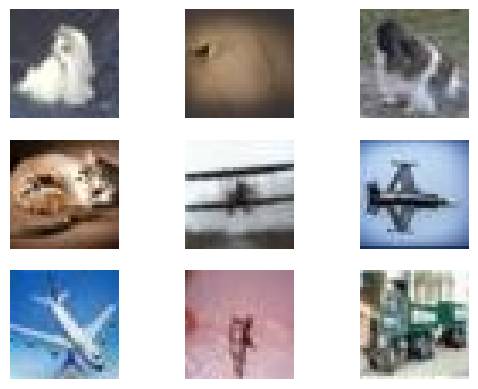

In [9]:
n_rows = 3
n_cols = 3
f, axarr = plt.subplots(n_rows, n_cols)
for row in range(n_rows):
    for col in range(n_cols):
      image = Image.open(data_df.sample(n = 1)['image_path'].iloc[0]).convert("RGB")
      axarr[row, col].imshow(image)
      axarr[row, col].axis('off')

plt.show()

Hyperparameters

In [10]:
LR = 1e-4
BATCH_SIZE = 16
EPOCHS = 10

DataLoaders

In [11]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=True)

Convolution model

In [17]:
class Net(nn.Module):
  def __init__(self):
    super().__init__()

    self.conv1 = nn.Conv2d(3, 32, kernel_size= 3)
    self.conv2 = nn.Conv2d(32, 64, kernel_size= 3)
    self.conv3 = nn.Conv2d(64, 128, kernel_size= 3)
    self.pooling = nn.MaxPool2d(2,2)
    self.relu = nn.ReLU()
    self.flatten = nn.Flatten()

    self._to_linear = None
    self.convs = nn.Sequential(
        self.conv1,
        self.pooling,
        self.relu,
        self.conv2,
        self.pooling,
        self.relu,
        self.conv3,
        self.pooling,
        self.relu,
    )

    with torch.no_grad():
        x = torch.randn(1, 3, 128, 128)
        x = self.convs(x)
        self._to_linear = x[0].shape[0] * x[0].shape[1] * x[0].shape[2]

    self.linear = nn.Linear(self._to_linear, 128)
    self.output = nn.Linear(128, len(data_df['labels'].unique()))

  def forward(self, x):
      x = self.convs(x)
      x = self.flatten(x)
      x = self.linear(x)
      x = self.output(x)

      return x

model = Net().to(device)

Optimizer

In [15]:
criterion = nn.CrossEntropyLoss()
optimizer = Adam(model.parameters(), lr=LR)

Training

In [19]:
total_loss_train_plot = []
total_loss_validation_plot = []
total_acc_train_plot = []
total_acc_validation_plot = []


for epoch in range(EPOCHS):
  total_acc_train = 0
  total_loss_train = 0
  total_loss_val = 0
  total_acc_val = 0

  for inputs, labels in train_loader:
    optimizer.zero_grad()
    outputs = model(inputs)
    train_loss = criterion(outputs, labels)
    total_loss_train += train_loss.item()
    train_loss.backward()

    train_acc = (torch.argmax(outputs, axis = 1) == labels).sum().item()
    total_acc_train += train_acc
    optimizer.step()

  with torch.no_grad():
    for inputs, labels in val_loader:
      outputs = model(inputs)
      val_loss = criterion(outputs, labels)
      total_loss_val += val_loss.item()

      val_acc = (torch.argmax(outputs, axis = 1) == labels).sum().item()
      total_acc_val += val_acc

  total_loss_train_plot.append(round(total_loss_train/1000, 4))
  total_loss_validation_plot.append(round(total_loss_val/1000, 4))
  total_acc_train_plot.append(round(total_acc_train/(train_dataset.__len__())*100, 4))
  total_acc_validation_plot.append(round(total_acc_val/(val_dataset.__len__())*100, 4))
  print(f'''Epoch {epoch+1}/{EPOCHS}, Train Loss: {round(total_loss_train/100, 4)} Train Accuracy {round((total_acc_train)/train_dataset.__len__() * 100, 4)}
              Validation Loss: {round(total_loss_val/100, 4)} Validation Accuracy: {round((total_acc_val)/val_dataset.__len__() * 100, 4)}''')
  print("="*25)

KeyboardInterrupt: 

Testing

In [ ]:
with torch.no_grad():
  total_loss_test = 0
  total_acc_test = 0
  for inputs, labels in test_loader:
    predictions = model(inputs)

    acc = (torch.argmax(predictions, axis = 1) == labels).sum().item()
    total_acc_test += acc
    test_loss = criterion(predictions, labels)
    total_loss_test += test_loss.item()

print(f"Accuracy Score is: {round((total_acc_test/test_dataset.__len__()) * 100, 4)} and Loss is {round(total_loss_test/1000, 4)}")


Plotting

In [ ]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

axs[0].plot(total_loss_train_plot, label='Training Loss')
axs[0].plot(total_loss_validation_plot, label='Validation Loss')
axs[0].set_title('Training and Validation Loss over Epochs')
axs[0].set_xlabel('Epochs')
axs[0].set_ylabel('Loss')
axs[0].legend()

axs[1].plot(total_acc_train_plot, label='Training Accuracy')
axs[1].plot(total_acc_validation_plot, label='Validation Accuracy')
axs[1].set_title('Training and Validation Accuracy over Epochs')
axs[1].set_xlabel('Epochs')
axs[1].set_ylabel('Accuracy')
axs[1].legend()

plt.tight_layout()

plt.show()

Inference

In [ ]:
def predict_image(image_path):
  image = Image.open(image_path).convert('RGB')
  image = transform(image).to(device)

  output = model(image.unsqueeze(0))
  output = torch.argmax(output, axis = 1).item()
  return label_encoder.inverse_transform([output])

image = Image.open("/content/cifake-real-and-ai-generated-synthetic-images/test/FAKE/113 (10).jpg")
plt.imshow(image)
plt.show()

print()
print("Prediction: \n")
predict_image("/content/cifake-real-and-ai-generated-synthetic-images/test/FAKE/113 (10).jpg")